# Листок № 3. Прикладные дифференциальные уравнения

Решены **все задачи 3.1–3.5**: аналитический вывод, проверяемые формулы, статические рисунки и управляемые анимации. Источник условий — «Практические занятия Листок 3.pdf», составитель П. Е. Рябов. Графики сохраняются в папку `listok3_figures` рядом с ноутбуком; они также видны прямо в сохранённом `.ipynb`.

**Как смотреть анимации:** выполните ноутбук локально в Jupyter. Под каждой анимацией встроены кнопки запуска, паузы и ползунок кадров. Всё строится без обращения к интернету после установки библиотек. GitHub показывает сохранённые статические графики, но может не исполнять встроенный JavaScript анимаций.

Во всех механических задачах предполагаем идеальную модель: без трения и сопротивления воздуха, если прямо не сказано иное. Ускорение свободного падения $g=9{,}81\,\text{м/с}^2$.

In [1]:
# Если необходимо, заранее установите библиотеки: %pip install numpy scipy matplotlib ipython
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from scipy.integrate import solve_ivp
from scipy.special import ellipk

g=9.81
FIG_DIR=Path('listok3_figures')
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':75,'font.size':10,'axes.grid':True,'grid.alpha':.25})

def show_animation(anim):
    # to_jshtml встраивает кадры и кнопки воспроизведения/паузы в сам ноутбук.
    display(HTML(anim.to_jshtml()))
    plt.close(anim._fig)

## 3.1. Кривая равномерного вертикального спуска

Выберем $x$ горизонтально вправо, $y$ вертикально вверх. Пусть вертикальная скорость постоянна: $\dot y=-u<0$, $u>0$. Тогда $y(t)=y_0-ut$ и $\ddot y=0$. Частица движется без трения по гладкой кривой; её нормальная реакция $\mathbf N$ перпендикулярна касательной. Второй закон Ньютона: $m\ddot{\mathbf r}=(0,-mg)+\mathbf N$. Умножая скалярно на скорость, исключаем реакцию, так как $\mathbf N\cdot\dot{\mathbf r}=0$:
$$\frac{d}{dt}\frac{m}{2}(\dot x^2+\dot y^2)=-mg\dot y=mg u.$$
Поскольку $\dot y=-u$ не меняется, получаем **дифференциальное уравнение** $\dot x\ddot x=gu$, или $d(\dot x^2)/dt=2gu$. При начальной горизонтальной скорости $v_0\ge0$:
$$\dot x(t)=\sqrt{v_0^2+2gut},\qquad
x(t)=x_0+\frac{(v_0^2+2gut)^{3/2}-v_0^3}{3gu}.$$
Исключая $t=(y_0-y)/u$, получаем искомую **явную кривую** на ветви $x\ge x_0$:
$$\boxed{y(x)=y_0-\frac{[v_0^3+3gu(x-x_0)]^{2/3}-v_0^2}{2g}.}$$
При $v_0=0$ это ветвь полукубической параболы $x-x_0=(2g)^{3/2}(y_0-y)^{3/2}/(3gu)$. Начальная вертикальная скорость $-u$ предполагается заданной; точка не стартует из состояния полного покоя. Подстановка в уравнение энергии даёт $\dot x^2+u^2=v_0^2+u^2+2g(y_0-y)$. Для кривой гладкой без перегибов реакция может обеспечить требуемое движение.

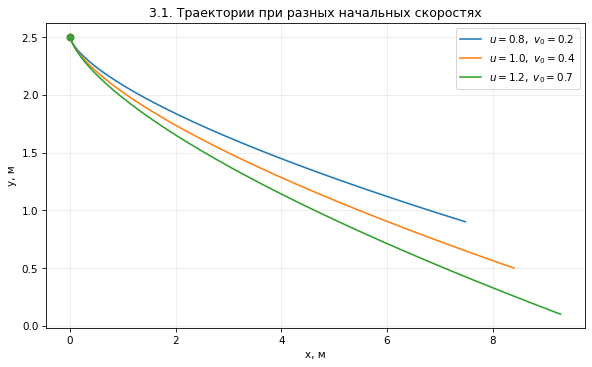

In [2]:
def descent_xy(t,u=1.0,v0=0.4,x0=0.,y0=2.5):
    t=np.asarray(t)
    x=x0+((v0*v0+2*g*u*t)**1.5-v0**3)/(3*g*u)
    y=y0-u*t
    return x,y

ts=np.linspace(0,2,400)
fig,ax=plt.subplots(figsize=(8,5))
for u,v0 in [(0.8,0.2),(1.0,0.4),(1.2,0.7)]:
    xx,yy=descent_xy(ts,u,v0)
    ax.plot(xx,yy,label=fr'$u={u},\ v_0={v0}$')
    ax.scatter([xx[0]],[yy[0]],s=40)
ax.set(xlabel='x, м',ylabel='y, м',title='3.1. Траектории при разных начальных скоростях')
ax.legend();fig.tight_layout();fig.savefig(FIG_DIR/'3_1_spusk.png',dpi=160);plt.show()
v0,u=.4,1.
xcheck,ycheck=descent_xy(ts,u,v0)
assert np.allclose(ycheck,2.5-u*ts)
assert np.allclose((v0*v0+2*g*u*ts)+u*u,v0*v0+u*u+2*g*(2.5-ycheck))

In [3]:
tt=np.linspace(0,2,40); pathx,pathy=descent_xy(np.linspace(0,2,300),1.,.4)
fig,ax=plt.subplots(figsize=(7,4));ax.plot(pathx,pathy,color='steelblue',label='Кривая')
point,=ax.plot([],[],'o',color='crimson',ms=10,label='Точка')
info=ax.text(.02,.04,'',transform=ax.transAxes)
ax.set(xlim=(0,max(pathx)*1.05),ylim=(min(pathy)-.2,2.8),xlabel='x, м',ylabel='y, м',title='Равномерный вертикальный спуск')
ax.legend()
def frame31(k):
    x,y=descent_xy(tt[k],1.,.4)
    point.set_data([x],[y]);info.set_text(f't={tt[k]:.2f} c, y={y:.2f} м, vy=-1.00 м/с')
    return point,info
anim31=FuncAnimation(fig,frame31,frames=len(tt),interval=75,blit=True)
show_animation(anim31)

## 3.2. Бильярд в прямоугольнике

Пусть стол имеет стороны $a,b$, координаты шара $(x,y)\in[0,a]\times[0,b]$, скорость между ударами постоянна: $\dot x=v_x$, $\dot y=v_y$. При упругом ударе о вертикальную стенку $v_x\mapsto-v_x$, $v_y$ сохраняется; о горизонтальную — наоборот. Энергия $H=(p_x^2+p_y^2)/(2m)$ сохраняется, а внутри области выполняются гамильтоновы уравнения $\dot x=p_x/m$, $\dot p_x=0$ (аналогично для $y$). На стенках импульс отражается зеркально; в вершине прямоугольника идеальная модель отражения неоднозначна.

**Метод развёртки:** вместо отражения шара отражаем прямоугольники. В развёрнутой плоскости траектория — прямая $X=x_0+v_xt$, $Y=y_0+v_yt$. Возврат в исходный прямоугольник даёт треугольная функция
$$x(t)=a-|((X\bmod2a)-a)|,\qquad y(t)=b-|((Y\bmod2b)-b)|.$$
Координаты $X\bmod2a$, $Y\bmod2b$ задают прямолинейное движение на плоском торе $\mathbb R^2/(2a\mathbb Z\times2b\mathbb Z)$.

Если $v_x,v_y\ne0$ и отношение $(v_x/a)/(v_y/b)$ рационально, движение на торе периодично; при иррациональном отношении оно плотно и равномерно распределено на торе (для обычной траектории без попадания в вершину), а отражённая траектория плотно покрывает прямоугольник. **Уточнение:** это не означает эргодичность всего бильярдного фазового потока: направление скорости остаётся инвариантом и разделяет фазовое пространство на семейства траекторий.

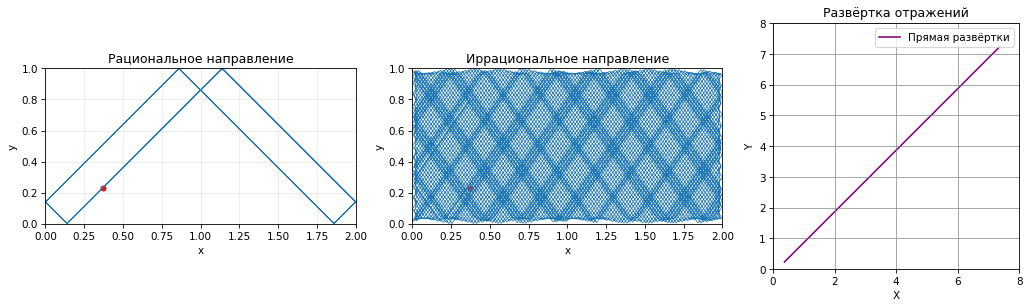

In [4]:
a,b=2.,1.
def fold(q,length):
    return length-np.abs(np.mod(q,2*length)-length)
def billiard(t,vx,vy,x0=.37,y0=.23):
    X=x0+vx*np.asarray(t);Y=y0+vy*np.asarray(t)
    return fold(X,a),fold(Y,b),X,Y

t=np.linspace(0,180,10000)
fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained')
for ax,vy,title,end in [(axes[0],1.,'Рациональное направление',14),(axes[1],np.sqrt(2),'Иррациональное направление',180)]:
    ti=np.linspace(0,end,4000);xx,yy,_,_=billiard(ti,1.,vy)
    ax.plot(xx,yy,lw=.75);ax.scatter([xx[0]],[yy[0]],color='red',s=22)
    ax.set(title=title,xlim=(0,a),ylim=(0,b),xlabel='x',ylabel='y');ax.set_aspect('equal')
_,_,X,Y=billiard(np.linspace(0,7,500),1.,1.)
axes[2].plot(X,Y,color='purple',label='Прямая развёртки')
for h in np.arange(0,9,a):axes[2].axvline(h,color='gray',lw=.6)
for h in np.arange(0,9,b):axes[2].axhline(h,color='gray',lw=.6)
axes[2].set(title='Развёртка отражений',xlabel='X',ylabel='Y',xlim=(0,8),ylim=(0,8));axes[2].set_aspect('equal');axes[2].legend()
fig.savefig(FIG_DIR/'3_2_bilyard.png',dpi=160);plt.show()
assert np.all((billiard(t,1.,1.)[0]>=0)&(billiard(t,1.,1.)[0]<=a))
assert np.all((billiard(t,1.,1.)[1]>=0)&(billiard(t,1.,1.)[1]<=b))

In [5]:
bt=np.linspace(0,28,40)
fig,axes=plt.subplots(1,3,figsize=(11,3.7),layout='constrained')
colors=['#1f77b4','#d62728'];vys=[1.,np.sqrt(2)]
points=[];trails=[]
for j in range(2):
    ax=axes[j];ax.set(xlim=(0,a),ylim=(0,b),xlabel='x',ylabel='y',title=['Периодическое','Иррациональное'][j]);ax.set_aspect('equal')
    tr,=ax.plot([],[],lw=1,color=colors[j]);pt,=ax.plot([],[],'o',color=colors[j]);trails.append(tr);points.append(pt)
axes[2].set(xlim=(0,2*a),ylim=(0,2*b),xlabel='X mod 2a',ylabel='Y mod 2b',title='Развёртка на торе');axes[2].set_aspect('equal')
torus_pts=[axes[2].plot([],[],'o',color=c,label=label)[0] for c,label in zip(colors,['рациональное','иррациональное'])]
axes[2].legend(loc='upper right',fontsize=8)
info=fig.text(.02,.01,'')
def frame32(k):
    for j,vy in enumerate(vys):
        tt=bt[:k+1];x,y,X,Y=billiard(tt,1.,vy)
        trails[j].set_data(x,y);points[j].set_data([x[-1]],[y[-1]])
        torus_pts[j].set_data([X[-1]%(2*a)],[Y[-1]%(2*b)])
    info.set_text(f't={bt[k]:.2f}; vx=1; vy=1 или √2; отражения упругие')
    return (*trails,*points,*torus_pts,info)
anim32=FuncAnimation(fig,frame32,frames=len(bt),interval=80,blit=True)
show_animation(anim32)

## 3.3. Цепная линия

Пусть вес нити на единицу длины $w=\rho g$, где $\rho$ — линейная плотность. Рассмотрим элемент нити. Горизонтальная составляющая натяжения $H=T_x$ постоянна, поскольку горизонтальных распределённых сил нет. Обозначим через $s$ **знаковую** длину дуги от нижней точки: справа $s>0$, слева $s<0$. Тогда вертикальная составляющая натяжения $T_y=ws$. Угол касательной удовлетворяет $y'=T_y/H$. Так как $ds/dx=\sqrt{1+y'^2}$,
$$\boxed{y''=\frac{w}{H}\sqrt{1+y'^2}=\frac1a\sqrt{1+y'^2},\qquad a=\frac{H}{\rho g}.}$$
Разделяем переменные: $dy'/\sqrt{1+y'^2}=dx/a$. После интегрирования $\operatorname{arsinh}y'=(x-x_c)/a$; значит $y'=\sinh((x-x_c)/a)$ и
$$\boxed{y(x)=a\cosh\!\left(\frac{x-x_c}{a}\right)+C.}$$
При симметричных опорах $x=\pm L$, $y=0$ берём $x_c=0$, $C=-a\cosh(L/a)$; провисание $d=a[\cosh(L/a)-1]$. Чем больше $H$ при той же $\rho$, тем больше $a$ и тем меньше провисание. Физически при **фиксированной длине цепи** $a$ определяется длиной и геометрией опор, поэтому при изменении $a$ на рисунке подразумевается изменение доступной длины или натяжения.

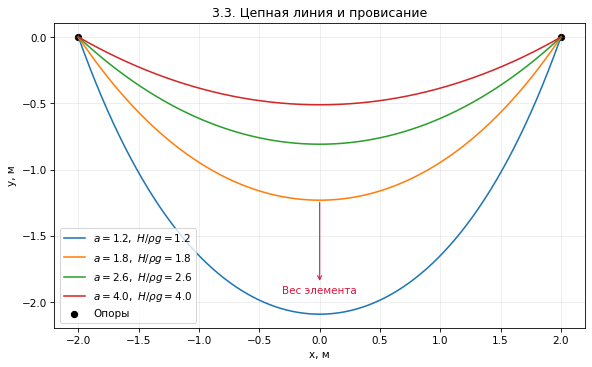

In [6]:
L=2.
def chain(x,a): return a*(np.cosh(np.asarray(x)/a)-np.cosh(L/a))
xs=np.linspace(-L,L,500)
fig,ax=plt.subplots(figsize=(8,5))
for aval in (1.2,1.8,2.6,4.):
    ax.plot(xs,chain(xs,aval),label=fr'$a={aval:.1f},\ H/\rho g={aval:.1f}$')
ax.scatter([-L,L],[0,0],color='black',label='Опоры')
ax.annotate('Вес элемента',xy=(0,chain(0,1.8)),xytext=(0,chain(0,1.8)-.7),arrowprops={'arrowstyle':'<-','color':'crimson'},color='crimson',ha='center')
ax.set(xlabel='x, м',ylabel='y, м',title='3.3. Цепная линия и провисание');ax.legend()
fig.tight_layout();fig.savefig(FIG_DIR/'3_3_tsepnaya_liniya.png',dpi=160);plt.show()
assert np.allclose(chain(np.array([-L,L]),1.8),0)

In [7]:
avals=2.5+1.15*np.sin(np.linspace(0,2*np.pi,40))
fig,ax=plt.subplots(figsize=(7,4));line,=ax.plot([],[],lw=2,color='navy')
ax.scatter([-L,L],[0,0],color='black');force=ax.annotate('',xy=(0,-.3),xytext=(0,0),arrowprops={'arrowstyle':'->','color':'crimson','lw':2})
info=ax.text(.02,.04,'',transform=ax.transAxes)
ax.set(xlim=(-2.2,2.2),ylim=(-2.7,.5),xlabel='x, м',ylabel='y, м',title='Изменение натяжения и формы цепи')
def frame33(k):
    aa=avals[k];yy=chain(xs,aa);line.set_data(xs,yy)
    ymid=chain(0,aa);force.xy=(0,ymid-.38);force.set_position((0,ymid))
    info.set_text(f'a=H/(ρg)={aa:.2f} м; провисание={-ymid:.2f} м; H∝a')
    return line,force,info
anim33=FuncAnimation(fig,frame33,frames=len(avals),interval=90,blit=False)
show_animation(anim33)

## 3.4. Таутохрона: циклоидальная кривая

Пусть $y\ge0$ — **высота над нижней точкой**, а $s$ — длина дуги, отсчитанная от неё вверх вдоль одной ветви. Частица стартует из покоя на высоте $Y$. Из закона энергии $\dot s^2=2g(Y-y)$, поэтому время до нижней точки
$$T(Y)=\frac1{\sqrt{2g}}\int_0^Y\frac{s'(y)}{\sqrt{Y-y}}\,dy.$$
Требуем $T(Y)=T_0$ для всех $Y$. Это интегральное уравнение Абеля. Если $F(y)=s'(y)$, его обратная формула даёт
$$F(y)=\frac1\pi\frac{d}{dy}\int_0^y\frac{T_0\sqrt{2g}}{\sqrt{y-v}}\,dv
=\frac{T_0\sqrt{2g}}{\pi\sqrt y}.$$
Следовательно, $s(y)=2T_0\sqrt{2gy}/\pi$, то есть $y=s^2/(8a)$ при $a=gT_0^2/\pi^2$. Тогда уравнение движения вдоль дуги становится гармоническим:
$$\ddot s+\frac{g}{4a}s=0,\qquad \omega=\sqrt{\frac{g}{4a}},\qquad T_0=\frac{\pi}{2\omega}=\pi\sqrt{\frac ag}.$$
Отсюда независимо от начальной дуговой координаты $s_0$: $s(t)=s_0\cos(\omega t)$ до прибытия в нижнюю точку. Соотношение $y=s^2/(8a)$ реализуется **циклоидой**
$$\boxed{x=a(\theta+\sin\theta),\qquad y=a(1-\cos\theta),\qquad -\pi\le\theta\le\pi,}$$
где $s=4a\sin(\theta/2)$ со знаком ветви. Внизу $\theta=0$. Без трения все шарики, отпущенные из покоя с разных точек одной ветви, достигают низа через одно и то же время $T_0$. На концах $\theta=\pm\pi$ находятся заострения.

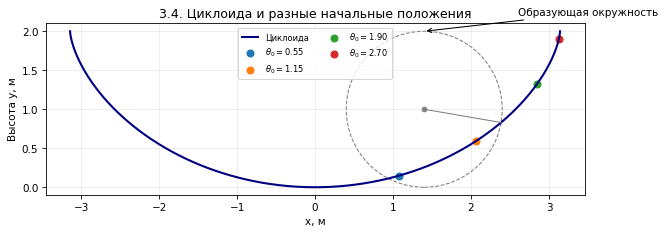

Одинаковое время прибытия: 1.0030333403553235 с


In [8]:
a_c=1.
def cycloid(theta,a=a_c):
    th=np.asarray(theta)
    return a*(th+np.sin(th)),a*(1-np.cos(th))
theta=np.linspace(-np.pi,np.pi,800)
xc,yc=cycloid(theta)
fig,ax=plt.subplots(figsize=(9,5));ax.plot(xc,yc,lw=2,color='navy',label='Циклоида')
starts=[.55,1.15,1.9,2.7]
for th in starts:
    x0,y0=cycloid(th);ax.scatter([x0],[y0],s=45,label=fr'$\theta_0={th:.2f}$')
th_roll=1.4;cx=a_c*th_roll;cy=a_c
circle=plt.Circle((cx,cy),a_c,fill=False,ls='--',color='gray');ax.add_patch(circle)
ax.scatter([cx],[cy],s=20,color='gray');ax.plot([cx,cycloid(th_roll)[0]],[cy,cycloid(th_roll)[1]],color='gray',lw=1)
ax.annotate('Образующая окружность',xy=(cx,cy+a_c),xytext=(cx+1.2,cy+1.2),arrowprops={'arrowstyle':'->'})
ax.set(xlabel='x, м',ylabel='Высота y, м',title='3.4. Циклоида и разные начальные положения');ax.set_aspect('equal');ax.legend(ncol=2,fontsize=8)
fig.tight_layout();fig.savefig(FIG_DIR/'3_4_tautokhrona.png',dpi=160);plt.show()
omega=np.sqrt(g/(4*a_c));T_arrive=np.pi/(2*omega)
print('Одинаковое время прибытия:',T_arrive,'с')
assert np.isclose(T_arrive,np.pi*np.sqrt(a_c/g))

In [9]:
times=np.linspace(0,T_arrive,40)
fig,ax=plt.subplots(figsize=(8,4.5));ax.plot(xc,yc,color='navy',lw=1.5)
balls=[ax.plot([],[],'o',ms=9,label=f'θ₀={th:.2f}')[0] for th in starts]
circle=plt.Circle((0,a_c),a_c,fill=False,ls=':',color='gray');ax.add_patch(circle)
info=ax.text(.02,.04,'',transform=ax.transAxes)
ax.set(xlim=(-3.5,3.5),ylim=(-.15,2.4),xlabel='x, м',ylabel='y, м',title='Все шарики прибывают одновременно');ax.set_aspect('equal');ax.legend(fontsize=8)
def frame34(k):
    t=times[k]
    for ball,th0 in zip(balls,starts):
        s0=4*a_c*np.sin(th0/2);st=s0*np.cos(omega*t)
        th=2*np.arcsin(np.clip(st/(4*a_c),-1,1));x,y=cycloid(th)
        ball.set_data([x],[y])
    # Окружность показывает геометрическое построение независимо от движения шариков.
    cx=a_c*np.pi*k/(len(times)-1);circle.center=(cx,a_c)
    info.set_text(f't={t:.3f} с / T={T_arrive:.3f} с; до низа осталось {T_arrive-t:.3f} с')
    return (*balls,circle,info)
anim34=FuncAnimation(fig,frame34,frames=len(times),interval=85,blit=False)
show_animation(anim34)

## 3.5. Математический маятник

Пусть длина стержня $l$, угол $\theta$ отсчитывается от нижней вертикали. Касательная составляющая тяжести равна $-mg\sin\theta$, а касательное ускорение — $l\ddot\theta$. Поэтому
$$\boxed{\ddot\theta+\frac gl\sin\theta=0.}$$
При $|\theta|\ll1$ заменяем $\sin\theta\approx\theta$: $\theta(t)\approx\theta_0\cos(\sqrt{g/l}\,t)+(\dot\theta_0/\sqrt{g/l})\sin(\sqrt{g/l}\,t)$ и $T_{\rm small}=2\pi\sqrt{l/g}$. При большой амплитуде линейное приближение неточно. Из энергии
$$E=\frac12 ml^2\dot\theta^2+mgl(1-\cos\theta)=\text{const}$$
для колебаний с амплитудой $0<\theta_0<\pi$ получается **точный период через полный эллиптический интеграл первого рода**:
$$\boxed{T(\theta_0)=4\sqrt{\frac lg}\,K\!\left(\sin^2\frac{\theta_0}{2}\right),\quad K(m)=\int_0^{\pi/2}\frac{d\phi}{\sqrt{1-m\sin^2\phi}}.}$$
При $\theta_0\to0$ он стремится к $T_{\rm small}$, при $\theta_0\to\pi$ растёт без ограничения. На фазовой плоскости $(\theta,\dot\theta)$ сепаратриса имеет энергию $2mgl$ и уравнение $\dot\theta=\pm2\sqrt{g/l}\cos(\theta/2)$ для $-\pi\le\theta\le\pi$. Ниже неё — колебания; выше — вращения. На статических графиках и в анимации нелинейное уравнение решается численно методом `solve_ivp`.

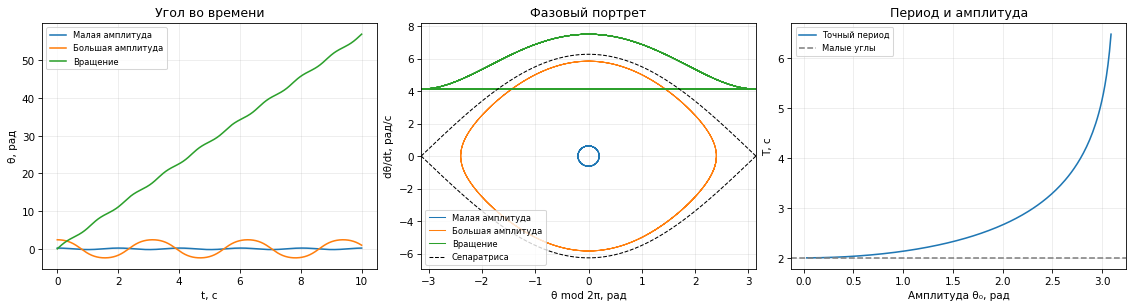

Период малых колебаний: 2.006066680710647 с; при амплитуде 2.4 рад: 3.129793431511672 с


In [10]:
l=1.;w0=np.sqrt(g/l)
def pendulum_rhs(t,state):
    th,velocity=state
    return [velocity,-g/l*np.sin(th)]
time=np.linspace(0,10,700)
cases=[(.2,0.,'Малая амплитуда'),(2.4,0.,'Большая амплитуда'),(0.,7.5,'Вращение')]
solutions=[solve_ivp(pendulum_rhs,(time[0],time[-1]),[th,v],t_eval=time,rtol=1e-10,atol=1e-12) for th,v,_ in cases]
amps=np.linspace(.03,np.pi-.05,200)
periods=4*np.sqrt(l/g)*ellipk(np.sin(amps/2)**2)
fig,axes=plt.subplots(1,3,figsize=(15,4),layout='constrained')
for sol,(_,_,label) in zip(solutions,cases):
    axes[0].plot(time,sol.y[0],label=label)
    axes[1].plot((sol.y[0]+np.pi)%(2*np.pi)-np.pi,sol.y[1],lw=1,label=label)
angles=np.linspace(-np.pi,np.pi,400);sep=2*w0*np.cos(angles/2)
axes[1].plot(angles,sep,'k--',lw=1,label='Сепаратриса');axes[1].plot(angles,-sep,'k--',lw=1)
axes[2].plot(amps,periods,label='Точный период');axes[2].axhline(2*np.pi/w0,color='gray',ls='--',label='Малые углы')
axes[0].set(title='Угол во времени',xlabel='t, с',ylabel='θ, рад');axes[0].legend(fontsize=8)
axes[1].set(title='Фазовый портрет',xlabel='θ mod 2π, рад',ylabel='dθ/dt, рад/с',xlim=(-np.pi,np.pi));axes[1].legend(fontsize=8)
axes[2].set(title='Период и амплитуда',xlabel='Амплитуда θ₀, рад',ylabel='T, с');axes[2].legend(fontsize=8)
fig.savefig(FIG_DIR/'3_5_mayatnik.png',dpi=160);plt.show()
for sol in solutions:
    energy=.5*l*l*sol.y[1]**2+g*l*(1-np.cos(sol.y[0]))
    assert np.max(np.abs(energy-energy[0]))<1e-6
print('Период малых колебаний:',2*np.pi/w0,'с; при амплитуде 2.4 рад:',4*np.sqrt(l/g)*ellipk(np.sin(1.2)**2),'с')

In [11]:
frames=np.linspace(0,8,44)
sol_small=solve_ivp(pendulum_rhs,(0,8),[.2,0],t_eval=frames,rtol=1e-10,atol=1e-12)
sol_large=solve_ivp(pendulum_rhs,(0,8),[2.4,0],t_eval=frames,rtol=1e-10,atol=1e-12)
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(9,4),layout='constrained')
ax1.set(xlim=(-1.3,1.3),ylim=(-1.3,.2),xlabel='x, м',ylabel='y, м',title='Малые и большие колебания');ax1.set_aspect('equal')
ax1.plot([0],[0],'ko');lines=[ax1.plot([],[],'o-',lw=2,label=name)[0] for name in ['θ₀=0.2','θ₀=2.4']];ax1.legend()
ax2.set(xlim=(-np.pi,np.pi),ylim=(-2*w0,2*w0),xlabel='θ, рад',ylabel='dθ/dt, рад/с',title='Синхронная фазовая плоскость')
ax2.plot(angles,sep,'k--',lw=1);ax2.plot(angles,-sep,'k--',lw=1)
dots=[ax2.plot([],[],'o')[0] for _ in range(2)]
info=fig.text(.04,.01,'')
def frame35(k):
    for line,dot,sol in zip(lines,dots,[sol_small,sol_large]):
        th,vel=sol.y[:,k]
        line.set_data([0,l*np.sin(th)],[0,-l*np.cos(th)])
        dot.set_data([th],[vel])
    info.set_text(f't={frames[k]:.2f} с; малый угол: θ={sol_small.y[0,k]:.2f}; большой угол: θ={sol_large.y[0,k]:.2f}')
    return (*lines,*dots,info)
anim35=FuncAnimation(fig,frame35,frames=len(frames),interval=80,blit=False)
show_animation(anim35)

## Итог и проверка

Задачи 3.1–3.5 решены аналитически, построены пять статических рисунков и пять управляемых анимаций. Встроенные `assert` проверяют законы движения и энергии. Все идеализации, выбор начальных условий и ограничения численных демонстраций указаны в соответствующих разделах.